TASK 08

OpenCV 5.0.0
image size (h, w, ch): (650, 1600, 3)
gray:      mean  133.7  std  80.9
equalized: mean  128.3  std  74.2


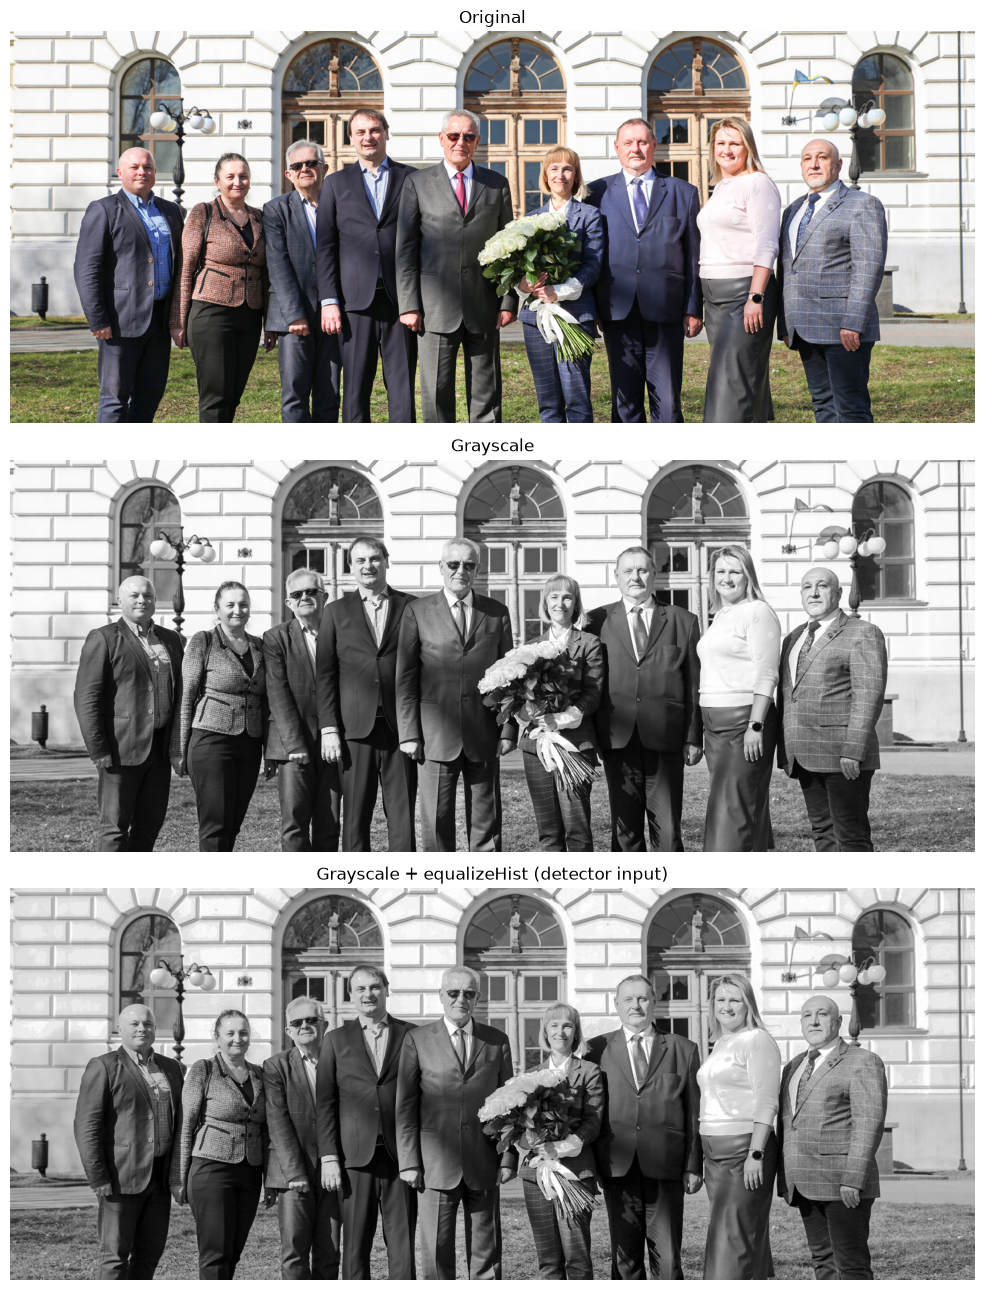

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt, csv, time
from pathlib import Path
print("OpenCV", cv2.__version__)

IMAGE_PATH   = Path("data") / "task08_group.jpg"
CASCADE_PATH = Path("data") / "cascades" / "haarcascade_frontalface_default.xml"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

img = cv2.imread(str(IMAGE_PATH))
assert img is not None, f"Cannot read {IMAGE_PATH}"
face_cascade = cv2.CascadeClassifier(str(CASCADE_PATH))
assert not face_cascade.empty(), f"Cascade not loaded: {CASCADE_PATH}"
print("image size (h, w, ch):", img.shape)      # keep the original size (no resize)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_eq = cv2.equalizeHist(gray)
print(f"gray:      mean {gray.mean():6.1f}  std {gray.std():5.1f}")
print(f"equalized: mean {gray_eq.mean():6.1f}  std {gray_eq.std():5.1f}")

fig, ax = plt.subplots(3, 1, figsize=(12, 13))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original")
ax[1].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Grayscale")
ax[2].imshow(gray_eq, cmap="gray", vmin=0, vmax=255); ax[2].set_title("Grayscale + equalizeHist (detector input)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task08_step1_preprocess.png", dpi=110); plt.show()

Step 2: Baseline detection (scaleFactor 1.1, minNeighbors 5)

scaleFactor=1.1, minNeighbors=5: 12 faces in 412.7 ms
 1  x= 187  y= 202  w= 60  h= 60
 2  x= 346  y= 219  w= 59  h= 59
 3  x= 384  y= 580  w= 38  h= 38
 4  x= 454  y= 195  w= 71  h= 71
 5  x= 561  y= 141  w= 67  h= 67
 6  x= 710  y= 146  w= 80  h= 80
 7  x= 884  y= 207  w= 58  h= 58
 8  x=1007  y= 159  w= 64  h= 64
 9  x=1100  y= 582  w= 61  h= 61
10  x=1160  y= 163  w= 62  h= 62
11  x=1301  y= 184  w= 69  h= 69
12  x=1411  y= 409  w=176  h=176


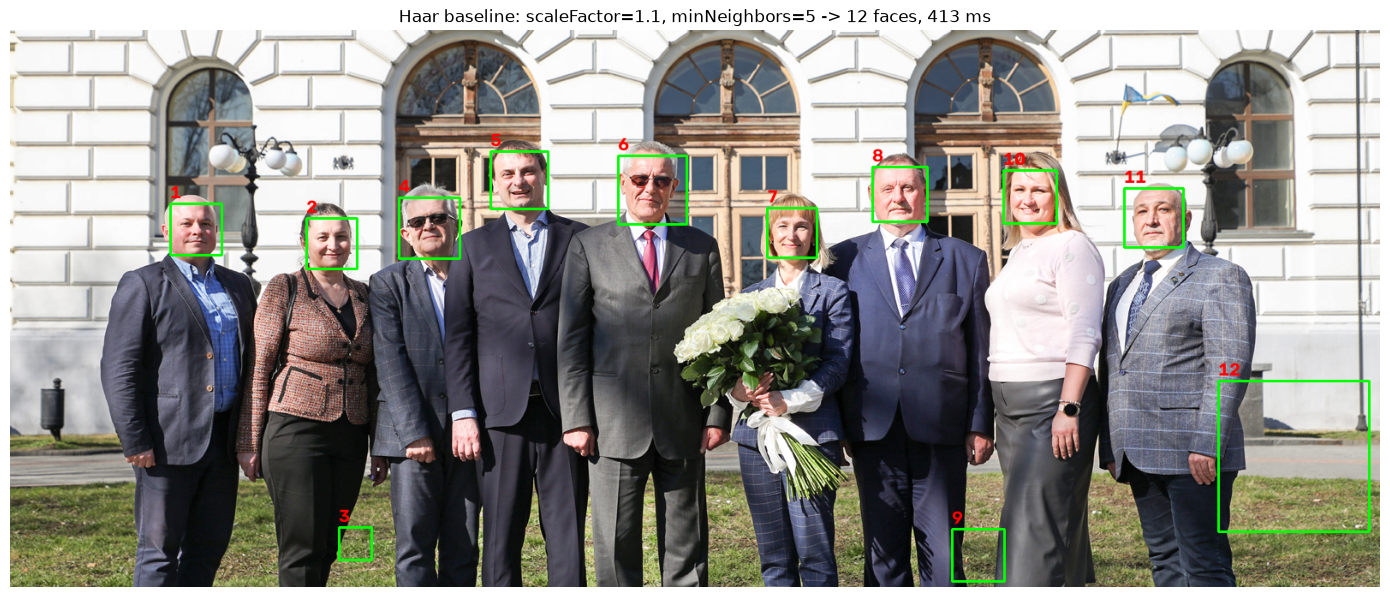

In [2]:
def detect_faces(gray_img, scale_factor, min_neighbors, min_size=(30, 30)):
    """Return list of (x, y, w, h). np.array(...).reshape(-1, 4) also handles the empty result ()."""
    res = face_cascade.detectMultiScale(gray_img, scaleFactor=scale_factor,
                                        minNeighbors=min_neighbors, minSize=min_size)
    return [tuple(int(v) for v in f) for f in np.array(res).reshape(-1, 4)]

SF, MN = 1.1, 5
t0 = time.perf_counter()
faces = detect_faces(gray_eq, SF, MN)
ms = (time.perf_counter() - t0) * 1000
print(f"scaleFactor={SF}, minNeighbors={MN}: {len(faces)} faces in {ms:.1f} ms")

vis = img.copy()
rows = []
for i, (x, y, w, h) in enumerate(sorted(faces), 1):          # sorted left -> right
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(vis, str(i), (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2, cv2.LINE_AA)
    rows.append([i, x, y, w, h])
    print(f"{i:2d}  x={x:4d}  y={y:4d}  w={w:3d}  h={h:3d}")

cv2.imwrite(str(RESULTS / "task08_faces_baseline.png"), vis)
with open(RESULTS / "task08_faces_baseline.csv", "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["id", "x", "y", "w", "h"]); wr.writerows(rows)

plt.figure(figsize=(14, 6)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"Haar baseline: scaleFactor={SF}, minNeighbors={MN} -> {len(faces)} faces, {ms:.0f} ms")
plt.axis("off"); plt.tight_layout(); plt.savefig(RESULTS / "task08_step2_baseline.png", dpi=110); plt.show()

Step 4–5: Evaluation and the 9-run experiment

In [3]:
# Ground truth = baseline boxes 1,2,4,5,6,7,8,10,11, verified visually (9 faces)
GT_FACES = [(187, 202, 60, 60), (346, 219, 59, 59), (454, 195, 71, 71), (561, 141, 67, 67),
            (710, 146, 80, 80), (884, 207, 58, 58), (1007, 159, 64, 64), (1160, 163, 62, 62),
            (1301, 184, 69, 69)]
IOU_THR = 0.3

def iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx))
    iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter)

def evaluate_faces(dets):
    """Label each detection true / duplicate / FALSE; return labels and counts."""
    labels, matched = [], set()
    for d in dets:
        scores = [iou(d, g) for g in GT_FACES]
        j = int(np.argmax(scores))
        if scores[j] >= IOU_THR:
            labels.append("duplicate" if j in matched else "true"); matched.add(j)
        else:
            labels.append("FALSE")
    tp = labels.count("true"); fp = labels.count("FALSE"); dup = labels.count("duplicate")
    return labels, tp, fp, dup, len(GT_FACES) - len(matched)

labels, tp, fp, dup, missed = evaluate_faces(faces)
print(f"baseline check: TP={tp}, FP={fp}, duplicates={dup}, missed={missed}")   # expect 9, 3, 0, 0

baseline check: TP=9, FP=3, duplicates=0, missed=0


Cell 4 (the experiment):

scaleFactor minNeighbors | det true  FP dup missed | time ms
       1.05            3 |  28    9  18   1      0 |   516.4
       1.05            5 |  22    9  13   0      0 |   384.9
       1.05            8 |  16    9   7   0      0 |   293.7
        1.1            3 |  17    9   8   0      0 |   137.4
        1.1            5 |  12    9   3   0      0 |   144.2
        1.1            8 |  10    9   1   0      0 |   204.6
        1.3            3 |  11    9   2   0      0 |    61.2
        1.3            5 |   8    8   0   0      1 |    64.0
        1.3            8 |   8    8   0   0      1 |    67.8


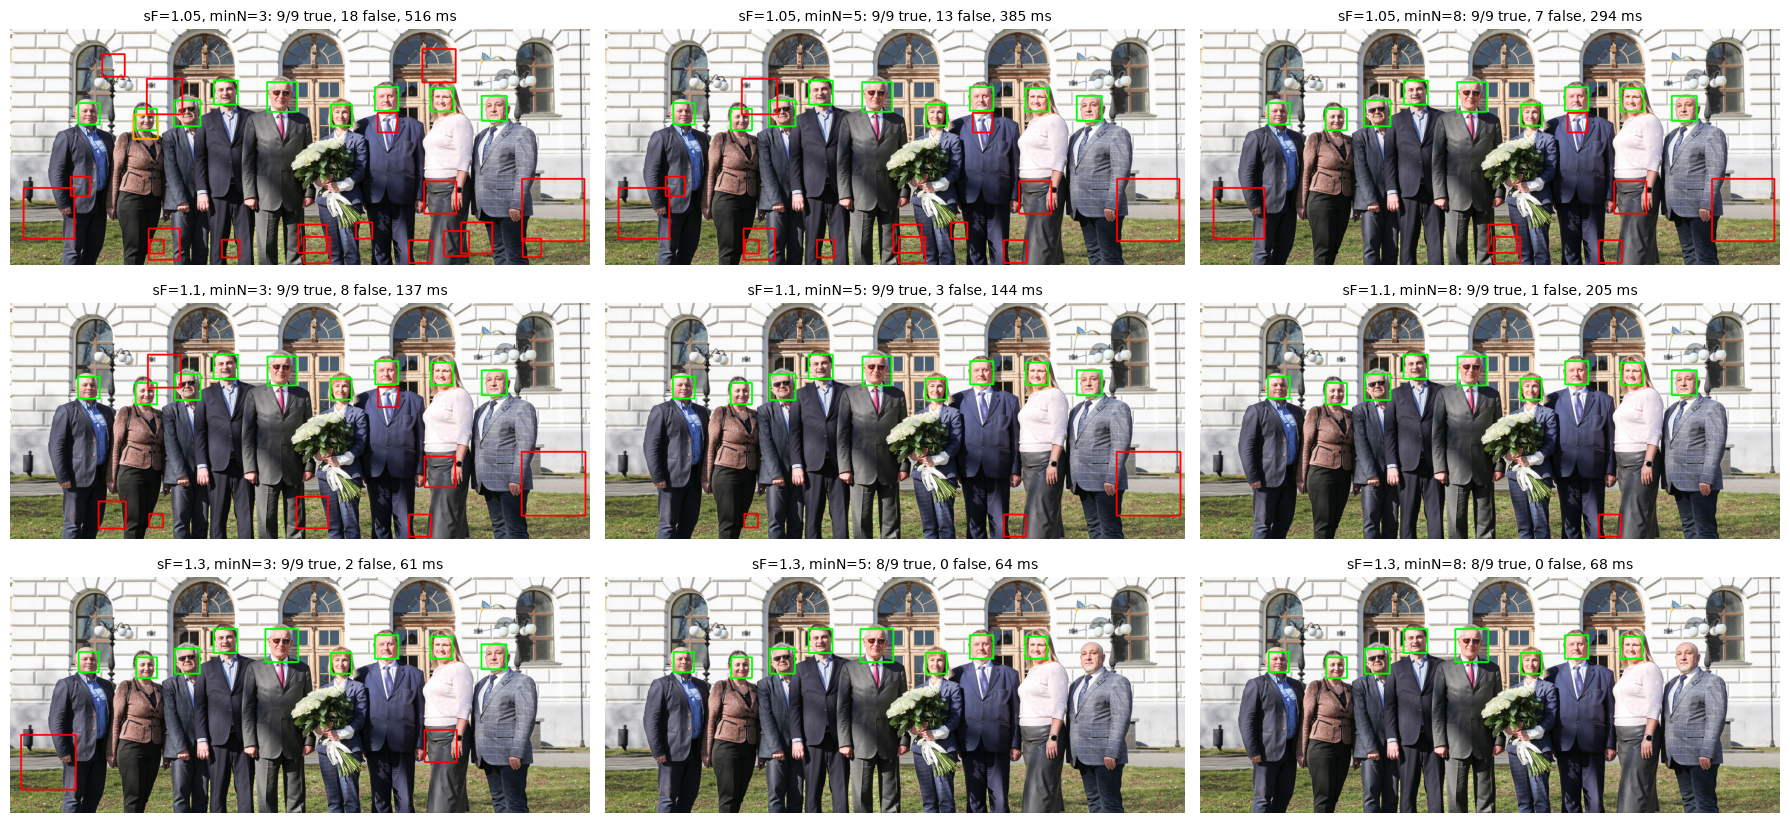

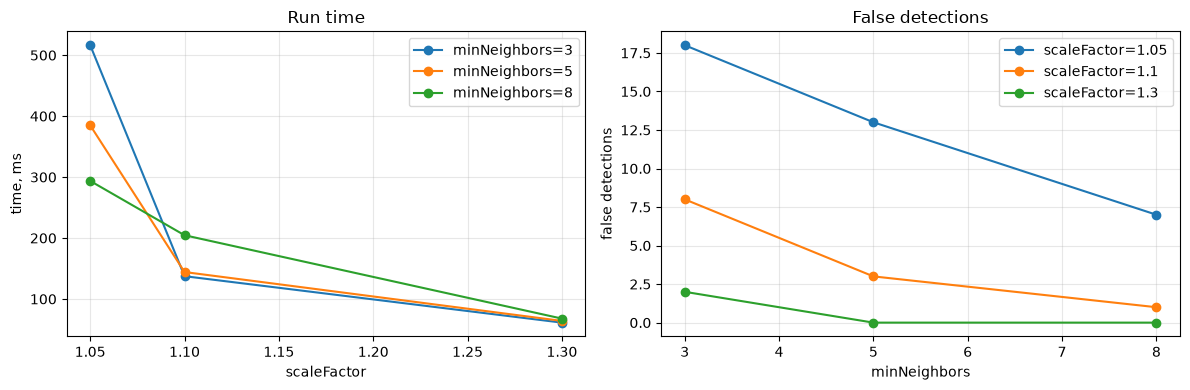

In [4]:
SCALES, NEIGHBORS, REPS = [1.05, 1.1, 1.3], [3, 5, 8], 3
results, grid_imgs = [], []

for sf in SCALES:
    for mn in NEIGHBORS:
        times = []
        for _ in range(REPS):                                  # median of 3 runs
            t0 = time.perf_counter()
            dets = detect_faces(gray_eq, sf, mn)
            times.append((time.perf_counter() - t0) * 1000)
        ms = float(np.median(times))
        labels, tp, fp, dup, missed = evaluate_faces(dets)
        results.append(dict(scaleFactor=sf, minNeighbors=mn, detections=len(dets), faces_true=tp,
                            false_pos=fp, duplicates=dup, missed=missed, time_ms=round(ms, 1)))
        v = img.copy()
        for (x, y, w, h), lab in zip(dets, labels):
            col = (0, 255, 0) if lab == "true" else (0, 165, 255) if lab == "duplicate" else (0, 0, 255)
            cv2.rectangle(v, (x, y), (x + w, y + h), col, 3)
        grid_imgs.append((sf, mn, tp, fp, ms, v))

print(f"{'scaleFactor':>11s} {'minNeighbors':>12s} | {'det':>3s} {'true':>4s} {'FP':>3s} {'dup':>3s} {'missed':>6s} | {'time ms':>7s}")
for r in results:
    print(f"{r['scaleFactor']:>11} {r['minNeighbors']:>12} | {r['detections']:3d} {r['faces_true']:4d} "
          f"{r['false_pos']:3d} {r['duplicates']:3d} {r['missed']:6d} | {r['time_ms']:7.1f}")

with open(RESULTS / "task08_experiment.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=list(results[0].keys())); wr.writeheader(); wr.writerows(results)

# 3x3 grid of results: green = true, red = false, orange = duplicate
fig, ax = plt.subplots(3, 3, figsize=(18, 8.5))
for a, (sf, mn, tp, fp, ms, v) in zip(ax.ravel(), grid_imgs):
    a.imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"sF={sf}, minN={mn}: {tp}/9 true, {fp} false, {ms:.0f} ms", fontsize=10)
plt.tight_layout(); plt.savefig(RESULTS / "task08_experiment_grid.png", dpi=110); plt.show()

# plots: time vs scaleFactor, false positives vs minNeighbors
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for mn in NEIGHBORS:
    rs = [r for r in results if r["minNeighbors"] == mn]
    ax[0].plot([r["scaleFactor"] for r in rs], [r["time_ms"] for r in rs], "o-", label=f"minNeighbors={mn}")
for sf in SCALES:
    rs = [r for r in results if r["scaleFactor"] == sf]
    ax[1].plot([r["minNeighbors"] for r in rs], [r["false_pos"] for r in rs], "o-", label=f"scaleFactor={sf}")
ax[0].set_xlabel("scaleFactor"); ax[0].set_ylabel("time, ms"); ax[0].set_title("Run time")
ax[1].set_xlabel("minNeighbors"); ax[1].set_ylabel("false detections"); ax[1].set_title("False detections")
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(RESULTS / "task08_experiment_plot.png", dpi=110); plt.show()